# 6. Covariables y disponibilidad

Se caracteriza el panel ampliado con observaciones meteorológicas e hidrológicas pasadas. Las asociaciones descriptivas no implican disponibilidad futura ni causalidad.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/processed/panel_horario.parquet').exists())
plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
panel = pq.read_table(ROOT/'data/processed/panel_horario.parquet', filters=[('inicio','<',pd.Timestamp('2022-01-01',tz='America/Bogota'))]).to_pandas()
assert panel.index.max() < pd.Timestamp('2022-01-01',tz='America/Bogota')
assert panel.index.is_monotonic_increasing and panel.index.is_unique
y = panel['y_demanda_real_kwh']
gwh = y / 1e6
registro = json.loads((ROOT/'data/processed/feature_registry.json').read_text(encoding='utf-8'))


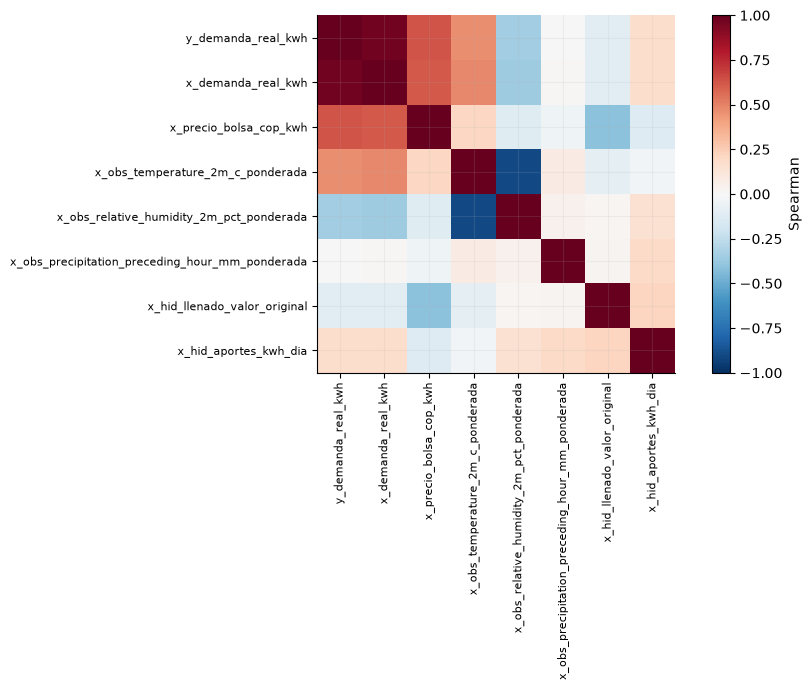

In [2]:
seleccion=['y_demanda_real_kwh','x_demanda_real_kwh','x_precio_bolsa_cop_kwh','x_obs_temperature_2m_c_ponderada','x_obs_relative_humidity_2m_pct_ponderada','x_obs_precipitation_preceding_hour_mm_ponderada','x_hid_llenado_valor_original','x_hid_aportes_kwh_dia']; correlacion=panel[seleccion].corr(method='spearman'); fig,ax=plt.subplots(figsize=(10,7)); im=ax.imshow(correlacion,vmin=-1,vmax=1,cmap='RdBu_r'); ax.set_xticks(range(len(seleccion)),labels=seleccion,rotation=90,fontsize=8); ax.set_yticks(range(len(seleccion)),labels=seleccion,fontsize=8); fig.colorbar(im,ax=ax,label='Spearman'); fig.tight_layout(); display(fig); plt.close(fig); asociacion=float(correlacion.loc['y_demanda_real_kwh','x_obs_temperature_2m_c_ponderada'])

La correlación de Spearman entre demanda y temperatura ponderada rezagada es 0.465. La matriz permite detectar asociaciones y redundancias; las tendencias compartidas y el calendario impiden interpretarlas como contribuciones causales.

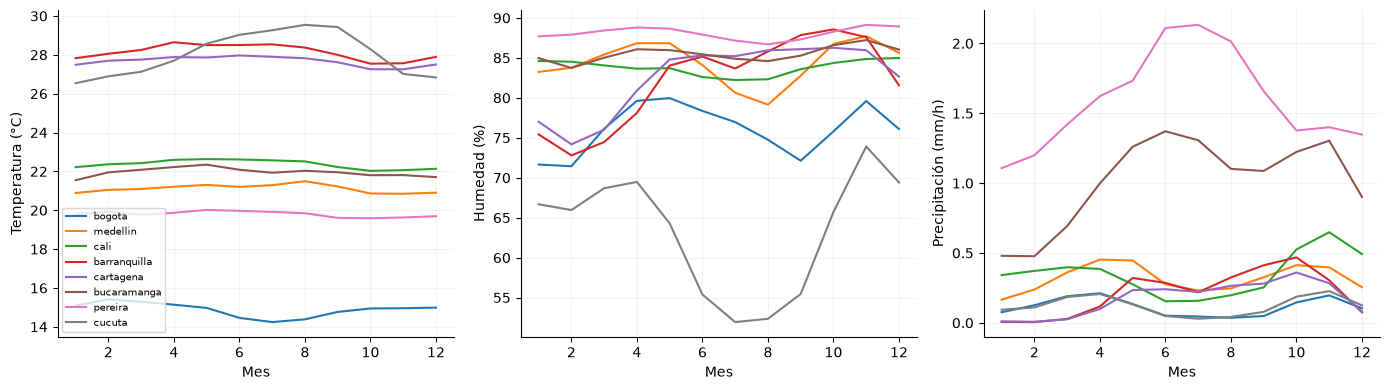

In [3]:
ciudades=['bogota','medellin','cali','barranquilla','cartagena','bucaramanga','pereira','cucuta']; fig,axes=plt.subplots(1,3,figsize=(14,4));
for ax,var,titulo in zip(axes,['temperature_2m_c','relative_humidity_2m_pct','precipitation_preceding_hour_mm'],['Temperatura (°C)','Humedad (%)','Precipitación (mm/h)']):
    for ciudad in ciudades:
        z=panel['x_obs_'+var+'_'+ciudad]; ax.plot(z.groupby(z.index.month).mean(),label=ciudad)
    ax.set(xlabel='Mes',ylabel=titulo)
axes[0].legend(fontsize=7); fig.tight_layout(); display(fig); plt.close(fig)

Los perfiles urbanos muestran heterogeneidad espacial y estacional. La ponderación por población resume ciudades, pero no describe lluvia en cuencas aportantes ni sustituye pronósticos con emisión previa. Los pesos estáticos de 2018 introducen una limitación temporal para años anteriores.

## Asociaciones disponibles al inicio del día

Las covariables se extraen de la fila anterior a cada origen diario. Se relacionan con la demanda media de las siguientes 24 horas. Las primeras diferencias reducen la influencia de tendencias comunes, aunque no eliminan estacionalidad ni demuestran causalidad.

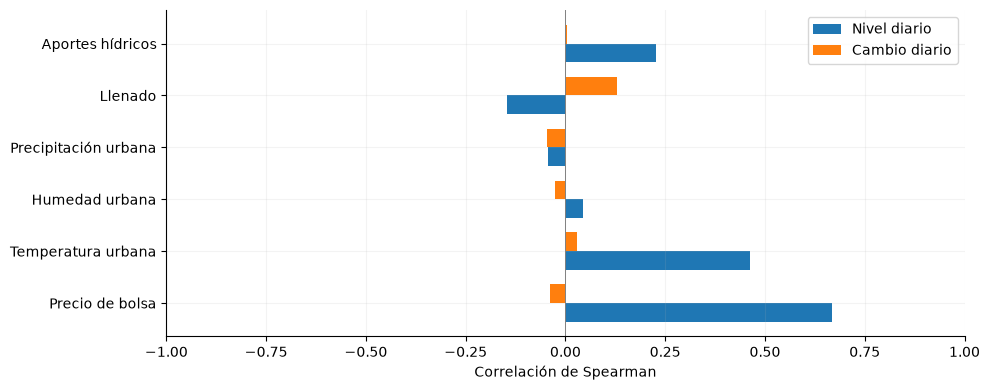

In [4]:
covars={
    'x_precio_bolsa_cop_kwh':'Precio de bolsa',
    'x_obs_temperature_2m_c_ponderada':'Temperatura urbana',
    'x_obs_relative_humidity_2m_pct_ponderada':'Humedad urbana',
    'x_obs_precipitation_preceding_hour_mm_ponderada':'Precipitación urbana',
    'x_hid_llenado_valor_original':'Llenado',
    'x_hid_aportes_kwh_dia':'Aportes hídricos'}
# Seleccionar la última fila permitida antes del origen de las 00:00.
diario=panel[list(covars)].shift(1).resample('D').asfreq()
diario['demanda']=gwh.resample('D').mean()
rho_nivel=diario.corr(method='spearman')['demanda'].drop('demanda')
rho_cambio=diario.diff().corr(method='spearman')['demanda'].drop('demanda')
pos=np.arange(len(covars)); fig,ax=plt.subplots(figsize=(10,4))
ax.barh(pos-.18,rho_nivel.reindex(covars),height=.36,label='Nivel diario')
ax.barh(pos+.18,rho_cambio.reindex(covars),height=.36,label='Cambio diario')
ax.set(yticks=pos,yticklabels=list(covars.values()),xlabel='Correlación de Spearman',xlim=(-1,1))
ax.axvline(0,color='grey',lw=.7); ax.legend(); fig.tight_layout(); display(fig); plt.close(fig)
etiqueta_cambio=covars[rho_cambio.abs().idxmax()]
valor_cambio=float(rho_cambio.loc[rho_cambio.abs().idxmax()])


La mayor asociación en cambios diarios corresponde a Llenado, con Spearman 0.13. Las diferencias entre nivel y cambio muestran cuánto depende cada relación de la evolución lenta de las series. La precipitación urbana describe condiciones locales de consumo; no sustituye la lluvia en las cuencas de los embalses.

## Respuesta meteorológica y calendario

Demanda y clima se centran descriptivamente por año, mes, día de semana y hora. Este ajuste separa parte del calendario y del crecimiento, pero utiliza todo el desarrollo y no se incorpora como transformación del entrenamiento.

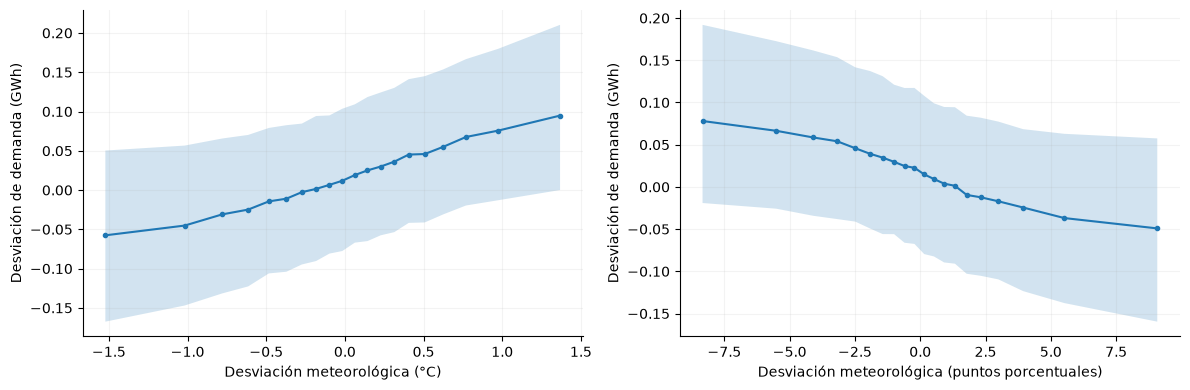

In [5]:
meteo=['x_obs_temperature_2m_c_ponderada','x_obs_relative_humidity_2m_pct_ponderada']
z=panel[meteo].shift(1).copy(); z['demanda']=gwh
grupos=[z.index.year,z.index.month,z.index.day_of_week,z.index.hour]
centrado=z-z.groupby(grupos).transform('mean')
fig,axes=plt.subplots(1,2,figsize=(12,4)); rhos=[]
for ax,col,unidad in zip(axes,meteo,['°C','puntos porcentuales']):
    a=centrado[[col,'demanda']].dropna(); bins=pd.qcut(a[col],20,duplicates='drop')
    curva=a.groupby(bins,observed=True).agg(x=(col,'median'),y=('demanda','median'),
        inferior=('demanda',lambda s:s.quantile(.25)),superior=('demanda',lambda s:s.quantile(.75)))
    ax.plot(curva.x,curva.y,marker='o',ms=3)
    ax.fill_between(curva.x.to_numpy(),curva.inferior.to_numpy(),curva.superior.to_numpy(),alpha=.2)
    ax.set(xlabel='Desviación meteorológica ('+unidad+')',ylabel='Desviación de demanda (GWh)')
    rhos.append(float(a[col].corr(a.demanda,method='spearman')))
fig.tight_layout(); display(fig); plt.close(fig)
rho_temp,rho_hum=rhos


Tras el centrado, las asociaciones de temperatura y humedad con demanda son 0.24 y -0.21. Las líneas muestran medianas por intervalos meteorológicos y las bandas el rango intercuartílico de demanda, no intervalos de confianza. La dispersión permite valorar la variabilidad que una relación media no resume.

## Estabilidad entre entrenamiento y validación

La distancia de Wasserstein compara distribuciones diarias de entrenamiento 2000–2017 y validación 2018–2021. Se divide por la desviación estándar de entrenamiento para comparar escalas; no se interpreta como prueba de hipótesis.

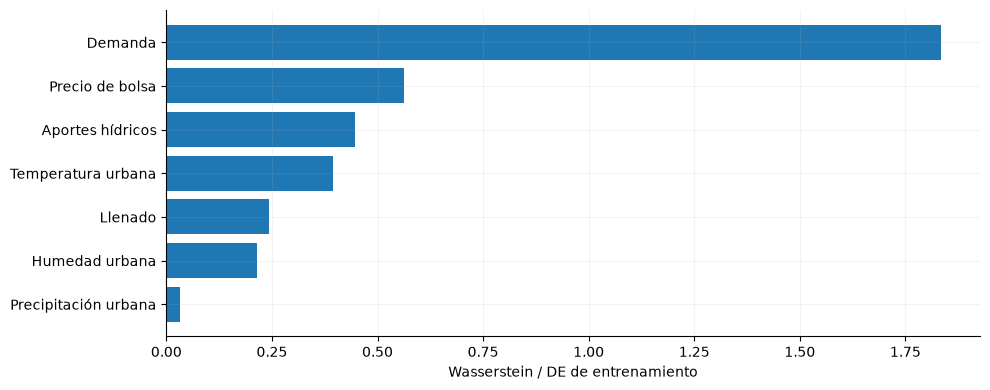

In [6]:
from scipy.stats import wasserstein_distance
ent=diario.loc[diario.index<'2018-01-01']; val=diario.loc[diario.index>='2018-01-01']
distancias={}
for col in ['demanda',*covars]:
    a=ent[col].dropna(); b=val[col].dropna(); sd=float(a.std())
    if sd>0 and len(b): distancias[col]=wasserstein_distance(a,b)/sd
drift=pd.Series(distancias).sort_values(); etiquetas={'demanda':'Demanda',**covars}
fig,ax=plt.subplots(); ax.barh([etiquetas[c] for c in drift.index],drift.values)
ax.set_xlabel('Wasserstein / DE de entrenamiento'); fig.tight_layout(); display(fig); plt.close(fig)
variable_drift=etiquetas[drift.idxmax()]; valor_drift=float(drift.max())


Demanda presenta el mayor desplazamiento normalizado (1.83). Una distancia elevada advierte que la validación puede exigir extrapolación; no demuestra por sí sola deterioro del pronóstico. Evaluar los años por separado permite identificar cambios de régimen que el agregado puede ocultar.

**Decisión.** Distinguir el conjunto de demanda y calendario del panel ampliado.

**Impacto.** Permite evaluar ampliaciones con una regla de disponibilidad explícita.

**Riesgo.** Reanálisis, población estática y revisiones de fuente pueden introducir sesgos retrospectivos.

## Prueba de desplazamiento entre particiones

Se contrasta igualdad de distribuciones mediante la máxima diferencia de CDF evaluada en 19 cuantiles del desarrollo agrupado, invariantes al intercambio de etiquetas de partición. Se permutan bloques completos de 28 días, con 1.999 permutaciones y Holm entre variables. Los bloques incompletos finales se excluyen del contraste. El procedimiento conserva dependencia dentro del bloque y supone intercambiabilidad aproximada entre bloques bajo la hipótesis nula; no utiliza horas como observaciones independientes.

In [7]:
# Contraste de CDF sobre 19 cuantiles, con permutación de bloques completos.
pruebas_drift=[];rng=np.random.default_rng(11039);bloque=28;B=1999
for col in ['demanda',*covars]:
    a=ent[col].dropna().to_numpy();b=val[col].dropna().to_numpy();na=len(a)//bloque;nb=len(b)//bloque
    cortes=np.quantile(np.r_[a[:na*bloque],b[:nb*bloque]],np.linspace(.05,.95,19));aa=a[:na*bloque].reshape(na,bloque);bb=b[:nb*bloque].reshape(nb,bloque)
    cdf=np.concatenate([(aa[:,:,None]<=cortes).mean(axis=1),(bb[:,:,None]<=cortes).mean(axis=1)])
    estadistico=np.max(np.abs(cdf[:na].mean(axis=0)-cdf[na:].mean(axis=0)));superan=0
    for _ in range(B):
        ix=rng.permutation(na+nb);t=np.max(np.abs(cdf[ix[:na]].mean(axis=0)-cdf[ix[na:]].mean(axis=0)));superan+=t>=estadistico-1e-12
    pruebas_drift.append({'variable':etiquetas[col],'dias_entrenamiento':na*bloque,'dias_validacion':nb*bloque,'D_CDF19':estadistico,'p_permutacion':(superan+1)/(B+1)})
pruebas_drift=pd.DataFrame(pruebas_drift);from statsmodels.stats.multitest import multipletests
pruebas_drift['p_Holm']=multipletests(pruebas_drift.p_permutacion,method='holm')[1];display(pruebas_drift.round(5))
pruebas_drift.to_csv(ROOT/'results/jbook/desplazamiento_formal.csv',index=False)


,variable,dias_entrenamiento,dias_validacion,D_CDF19,p_permutacion,p_Holm
0,Demanda,6552,1456,0.70292,0.0005,0.0035
1,Precio de bolsa,6552,1456,0.42140,0.0005,0.0035
2,Temperatura urbana,6552,1456,0.17575,0.0005,0.0035
3,Humedad urbana,6552,1456,0.09737,0.0455,0.1365
4,Precipitación urbana,6552,1456,0.02564,0.5800,0.7070
5,Llenado,6552,1456,0.10607,0.3535,0.7070
6,Aportes hídricos,6552,1456,0.15812,0.0105,0.0420


Los valores p ajustados complementan las distancias de Wasserstein: una distancia cuantifica magnitud y el contraste evalúa compatibilidad con igualdad bajo el esquema de permutación. La tendencia y los cambios de régimen pueden explicar un rechazo. No se deduce causalidad ni pérdida de precisión predictiva a partir de ese resultado. [Descargar resultados](_static/resultados/desplazamiento_formal.csv).

## Entradas comunes del diseño predictivo

La comparación con texto empleará el mismo conjunto numérico en todas sus variantes: demanda, calendario, clima de ocho ciudades, hidrología y precio. La especificación de disponibilidad, las máscaras y el presupuesto se presentan en el {ref}`diseño de entrenamiento ampliado <diseno-ampliado>`. La información realizada durante el horizonte queda excluida de las entradas.